# 02 Preprocessing
**Real Planet or False Alarm? Classifying Kepler Exoplanet Candidates**  
Keelan O'Dowd (23440916)

Here I design the preprocessing for my 13 core features and check it does what I think it does. No models yet, and only the training rows from notebook 01. The pipeline lives in `src/preprocessing.py`, so every later model uses exactly the same steps:

1. **Signed log** on the 11 long tailed features, to tame the extreme values from notebook 01 without deleting anything.
2. **Scaling**, so distance and coefficient based models see every feature on the same scale.
3. **Median imputation with missing value indicators**, so no rows are lost and the "fit failed" clue survives.

## 0. Setup

In [25]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold

from src.data import load_labelled
from src.features import CORE_FEATURES, FEATURE_UNITS, GROUP, LINEAR_FEATURES
from src.preprocessing import build_preprocessor, signed_log

RANDOM_STATE = 42
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})

## 1. Training set

In [26]:
labelled = load_labelled()
train = labelled[labelled["set"] == "train"].reset_index(drop=True)
del labelled

X_train = train[CORE_FEATURES]
y_train = train["y"]
groups_train = train[GROUP]

print(f"Training rows: {len(train):,} | stars: {groups_train.nunique():,} | "
      f"share confirmed: {y_train.mean():.3f}")

Training rows: 6,068 | stars: 5,306 | share confirmed: 0.362


c:\Users\keela\programming\machine_learning\Kepler-exoplanet-classification\src\data.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  labelled["y"] = (labelled["koi_disposition"] == "CONFIRMED").astype(int)


## 2. Which features need a log transform?

Skewness before and after. Close to 0 means roughly symmetric. Far from 0 means a long tail that would dominate scaling and distances.

In [27]:
feature_skewness = pd.DataFrame({
    "units": pd.Series(FEATURE_UNITS),
    "skew_raw": X_train.skew(),
    "skew_after_log": signed_log(X_train).skew(),
})
feature_skewness["transform"] = np.where(
    feature_skewness.index.isin(LINEAR_FEATURES), "none (already log scale)", "signed log"
)
feature_skewness.round(2).sort_values("skew_raw", ascending=False)

,units,skew_raw,skew_after_log,transform
koi_prad,Earth radii,53.69,1.17,signed log
koi_insol,Earth flux,42.38,0.17,signed log
koi_impact,dimensionless,27.20,3.05,signed log
koi_srad,Solar radii,22.37,4.14,signed log
koi_duration,hours,6.22,0.94,signed log
koi_depth,ppm,4.81,0.98,signed log
koi_model_snr,dimensionless,4.64,1.08,signed log
koi_teq,K,3.61,-0.04,signed log
koi_period,days,3.06,0.70,signed log
koi_num_transits,count,1.88,-0.62,signed log


**Decision:** log everything except `koi_slogg` and `koi_kepmag`, which are already logs. Nothing is negative, so the signed log is just log(1 + x) here and handles the zeros fine.

The log does most of the work. Planet radius drops from a skew of 53.7 to 1.2 and insolation from 42.4 to 0.2, while duration, depth and SNR all come down to about 1. Two stay skewed, `koi_impact` at 3.05 and `koi_srad` at 4.14, but their tails are real: badly fitted grazing signals, and giant stars up to 230 times the Sun's radius. I'm keeping them, though they're worth watching for k-NN later, where a few extreme values can dominate distances. The table also backs up leaving the two linear features alone, since logging them would make their skew worse.

## 3. Build the pipeline

In [28]:
preprocessor = build_preprocessor().set_output(transform="pandas")
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log', ...), ('linear', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. 

## 4. Fit on the training set and check it

In [29]:
preprocessed_features = preprocessor.fit_transform(X_train)

missing_indicator_columns = [
    column for column in preprocessed_features.columns
    if column.startswith("missingindicator_")
]
scaled_feature_columns = [
    column for column in preprocessed_features.columns
    if column not in missing_indicator_columns
]

assert not preprocessed_features.isna().any().any(), "missing values left after imputation"
assert len(preprocessed_features) == len(X_train), "rows were dropped"
for column in missing_indicator_columns:
    original_feature = column.removeprefix("missingindicator_")
    assert (preprocessed_features[column] == X_train[original_feature].isna()).all(), column
assert (preprocessed_features[scaled_feature_columns].mean().abs() < 0.1).all(), "a feature is not centred"
assert preprocessed_features[scaled_feature_columns].std().between(0.9, 1.1).all(), "a feature is not scaled"

print(f"Output shape: {preprocessed_features.shape} "
      f"({len(scaled_feature_columns)} features + {len(missing_indicator_columns)} missing indicators)")
print("Indicators created for:", [column.removeprefix("missingindicator_")
                                  for column in missing_indicator_columns])
preprocessed_features[scaled_feature_columns].describe().T[["mean", "std", "min", "max"]].round(2)

Output shape: (6068, 23) (13 features + 10 missing indicators)
Indicators created for: ['koi_depth', 'koi_impact', 'koi_model_snr', 'koi_num_transits', 'koi_prad', 'koi_teq', 'koi_insol', 'koi_steff', 'koi_srad', 'koi_slogg']


,mean,std,min,max
koi_period,0.00,1.00,-1.43,2.77
koi_duration,-0.00,1.00,-2.57,5.33
koi_depth,-0.01,0.98,-2.54,2.95
koi_impact,0.00,0.98,-1.37,12.88
koi_model_snr,-0.01,0.98,-2.40,3.08
koi_num_transits,0.01,0.96,-2.67,1.64
koi_prad,-0.02,0.99,-1.29,7.12
koi_teq,0.00,0.98,-3.31,4.04
koi_insol,-0.00,0.99,-1.97,4.23
koi_steff,0.00,0.98,-5.21,7.14


Every check passes: nothing missing, no rows lost, each indicator marks exactly the rows that were missing, and every feature is centred near 0 with a spread near 1. They're not exactly 0 and 1 because scaling happens before imputation and the filled values sit at the median.

That gives 23 columns: 13 features and 10 indicators. Eight of the indicators flag the exact same 207 rows where the transit fit failed, so they repeat one piece of information. Trees don't care, but logistic regression splits its weight across the copies, so I won't read those coefficients individually. The other two, for `koi_insol` and `koi_num_transits`, carry their own patterns.

## 5. Before and after

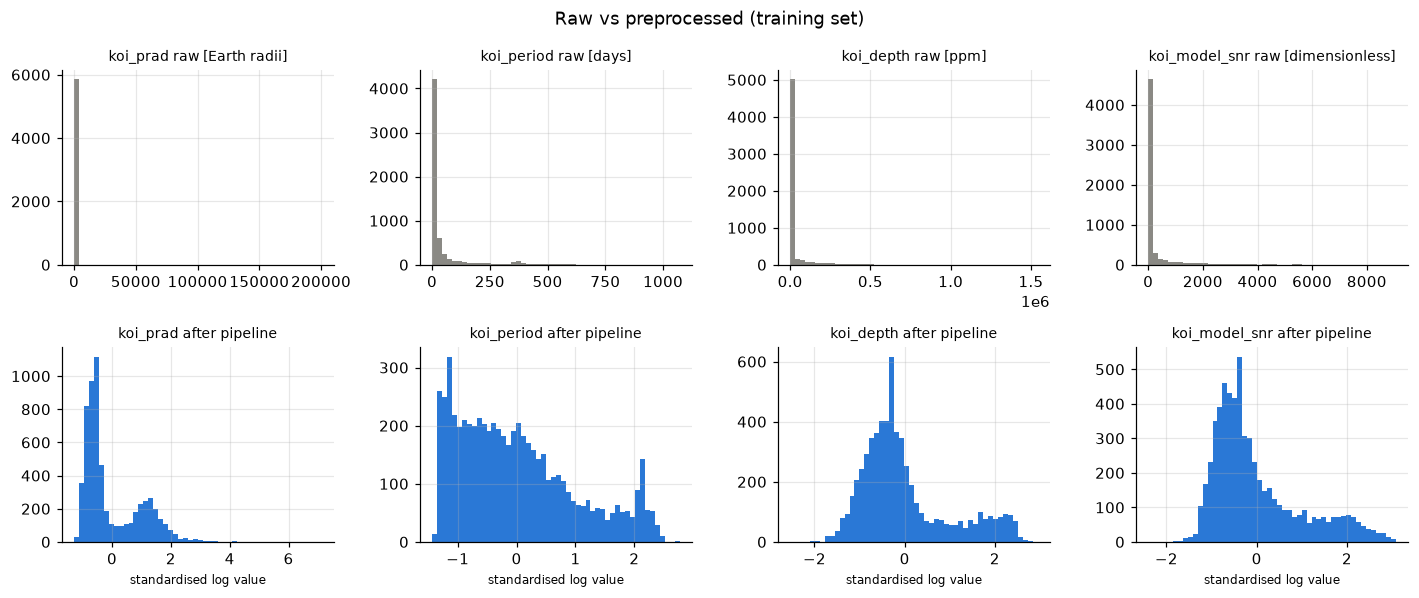

In [30]:
features_to_plot = ["koi_prad", "koi_period", "koi_depth", "koi_model_snr"]
fig, axes = plt.subplots(2, len(features_to_plot), figsize=(13, 5.5))
for column_index, feature_name in enumerate(features_to_plot):
    axes[0, column_index].hist(X_train[feature_name].dropna(), bins=50, color="#8a8984")
    axes[0, column_index].set_title(f"{feature_name} raw [{FEATURE_UNITS[feature_name]}]", fontsize=9)
    axes[1, column_index].hist(preprocessed_features[feature_name], bins=50, color="#2a78d6")
    axes[1, column_index].set_title(f"{feature_name} after pipeline", fontsize=9)
    axes[1, column_index].set_xlabel("standardised log value", fontsize=8)
fig.suptitle("Raw vs preprocessed (training set)")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_before_after.png", bbox_inches="tight")

On the raw scale every feature is a single spike near zero with a few enormous values. Planet radius goes up to 200,000 Earth radii, so you can't see anything. After the pipeline the shapes actually tell a story:

* **Planet radius has two humps:** real planet sizes, and a second group of huge objects that notebook 01 showed are almost all false positives.
* **Depth and SNR** have a long shoulder of deep, strong signals, which is what eclipsing binaries look like.
* **Period** has a sharp spike at about a year. That's likely a known Kepler artefact tied to the spacecraft's own 372 day orbit around the Sun, and in notebook 01 it was made of false positives.

The single tall bars in the middle of the radius and depth panels are the 207 filled in rows sitting at the median, and the indicators keep track of them.

## 6. Is the pipeline refitted in every fold?

The pipeline learns means, standard deviations and medians. Inside a `Pipeline`, cross-validation refits it on each training fold, so the held out fold never shapes its own preprocessing. Fitting it fold by fold shows this directly.

In [31]:
grouped_cv_splits = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
                         .split(X_train, y_train, groups=groups_train))
log_transformed_columns = preprocessor.transformers[0][2]
planet_radius_column_index = log_transformed_columns.index("koi_prad")

fold_summary_rows = []
for fold_number, (fitting_indices, validation_indices) in enumerate(grouped_cv_splits, start=1):
    fold_scaler = clone(preprocessor).fit(X_train.iloc[fitting_indices]).named_transformers_["log"]["scale"]
    fold_summary_rows.append({"fold": fold_number, "rows_fitted": len(fitting_indices),
                              "rows_held_out": len(validation_indices),
                              "koi_prad_learned_mean": fold_scaler.mean_[planet_radius_column_index],
                              "koi_prad_learned_std": np.sqrt(fold_scaler.var_[planet_radius_column_index])})
pd.DataFrame(fold_summary_rows).set_index("fold").round(4)

,rows_fitted,rows_held_out,koi_prad_learned_mean,koi_prad_learned_std
fold,,,,
1,4854,1214,1.9827,1.4446
2,4854,1214,1.9924,1.4415
3,4856,1212,1.9815,1.4245
4,4854,1214,1.9738,1.4301
5,4854,1214,1.9819,1.4400


Each fold learns slightly different values: the mean of log planet radius ranges from 1.974 to 1.992. The differences are small, so the folds are similar, but they're not zero, which shows the preprocessing never sees the held out data. `cross_validate` does this automatically for every model in notebook 03.

## 7. Does it matter whether I log or impute first?

A log keeps values in the same order, so the median should come out the same either way.

In [32]:
planet_radius_values = X_train["koi_prad"]
impute_then_log = signed_log(planet_radius_values.fillna(planet_radius_values.median()))
log_then_impute = signed_log(planet_radius_values).fillna(signed_log(planet_radius_values).median())
print(f"Largest difference between the two orders: "
      f"{(impute_then_log - log_then_impute).abs().max():.6f}")

Largest difference between the two orders: 0.000000


No difference at all. The order of the log step doesn't matter. What does matter is imputing after scaling, which keeps the indicators as clean 0 or 1 flags.

## Summary

* **Pipeline:** signed log on 11 features, then scaling, then median imputation with indicators, giving 13 features plus 10 indicators.
* **Evidence:** skew falls from as high as 54 to about 1 for most features. `koi_impact` and `koi_srad` keep real tails, which I've left alone.
* **Checks:** nothing missing, no rows lost, indicators correct, features scaled, and everything refitted per fold.
* **Next:** notebook 03 puts this in front of each baseline model.